In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configurações de visualização
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

sns.set_theme(style="whitegrid")

print("Bibliotecas carregadas com sucesso!")

Bibliotecas carregadas com sucesso!


# NutriRota — Análise exploratória da base Brancoli et al. (2022)

## 1. Contexto CitizenTech, objetivo e origem dos dados

O NutriRota investiga como dados podem apoiar a identificação e a destinação responsável de excedentes de alimentos, contribuindo para reduzir perdas e desperdício e fortalecer iniciativas de segurança alimentar.

Nesta primeira análise, o recorte é o desperdício de alimentos em **feiras livres de São Paulo**. A análise combina duas fontes com papéis diferentes:

- **Brancoli et al. (2022):** estudo de caracterização e pesagem de resíduos em quatro feiras livres paulistanas, com dados por categoria de resíduo e indicador em kg/barraca.
- **Prefeitura de São Paulo (PMSP):** relação municipal de feiras livres, usada para contextualizar territorialmente os quatro locais do estudo e explorar a distribuição municipal das feiras.

A integração entre as fontes é exploratória: as correspondências entre as quatro feiras do artigo e os registros municipais foram estabelecidas por nome, dia e bairro, mas não equivalem a uma confirmação por identificador oficial ou endereço publicado no artigo.

**Objetivo deste notebook:** compreender a composição do desperdício observado nas quatro feiras estudadas, comparar os indicadores por feira e documentar limites que devem orientar a próxima etapa de modelagem.

**Atenção:** kg/barraca é a unidade reportada na base transcrita do estudo. Volumes obtidos pela multiplicação desse indicador pelo número de barracas são cálculos derivados, não pesagens independentes de cada barraca.


## 2. Carregamento e integridade da base

Nesta seção, carregamos a base integrada e verificamos sua estrutura, completude e consistência antes de iniciar as análises.


In [2]:
# 1. Identificar a pasta principal do projeto
RAIZ = Path.cwd().parent

# 2. Localizar o arquivo CSV
CAMINHO_BASE = RAIZ / "data" / "processed" / "brancoli_2022_base_com_prefeitura.csv"

# 3. Carregar o arquivo para um DataFrame
df = pd.read_csv(CAMINHO_BASE, encoding="utf-8-sig")

# 4. Verificar a quantidade de registros e colunas
quantidade_registros = df.shape[0]
quantidade_colunas = df.shape[1]

print("Base carregada com sucesso!")
print(f"Quantidade de registros: {quantidade_registros}")
print(f"Quantidade de colunas: {quantidade_colunas}")

Base carregada com sucesso!
Quantidade de registros: 104
Quantidade de colunas: 19


In [3]:
# Visualizar os 10 primeiros registros
df.head(10)

,market_id,name,weekday,district,idh,number_of_stalls,category_level_I,category_level_II,kg_per_stall,classification,source_table,source_page,nome_feira_municipal,dia_feira_municipal,subprefeitura,bairro_municipal,tipo_logradouro,logradouro,status_correspondencia
0,SM1,Parque da Mooca,terça-feira,Parque da Mooca,0.819,4,Packaging,Packaging,2.00,packaging,Table 3,8,PARQUE DA MOOCA,TER,MOOCA,PQ DA MOOCA,RUA,CONDE PRATES,exploratoria_consistente
1,SM2,Sumaré Moderna,terça-feira,Pacaembú,0.868,73,Packaging,Packaging,3.07,packaging,Table 3,8,SUMARE MODERNA,TER,SE,PACAEMBU,PC,CHARLES MULLER,exploratoria_consistente
2,SM3,Baturité,quarta-feira,Aclimação,0.823,40,Packaging,Packaging,3.40,packaging,Table 3,8,BATURITE,QUA,SE,ACLIMACAO,RUA,OLIVEIRA PEIXOTO,exploratoria_consistente
3,SM4,Belém,quinta-feira,Belenzinho,0.790,39,Packaging,Packaging,5.89,packaging,Table 3,8,BELEM,QUI,MOOCA,BELENZINHO,RUA,IRMA CAROLINA,exploratoria_consistente
4,SM1,Parque da Mooca,terça-feira,Parque da Mooca,0.819,4,Leaves flowers and stems,Broccoli and cauliflower,0.00,avoidable_food_waste,Table 3,8,PARQUE DA MOOCA,TER,MOOCA,PQ DA MOOCA,RUA,CONDE PRATES,exploratoria_consistente
5,SM2,Sumaré Moderna,terça-feira,Pacaembú,0.868,73,Leaves flowers and stems,Broccoli and cauliflower,0.00,avoidable_food_waste,Table 3,8,SUMARE MODERNA,TER,SE,PACAEMBU,PC,CHARLES MULLER,exploratoria_consistente
6,SM3,Baturité,quarta-feira,Aclimação,0.823,40,Leaves flowers and stems,Broccoli and cauliflower,0.03,avoidable_food_waste,Table 3,8,BATURITE,QUA,SE,ACLIMACAO,RUA,OLIVEIRA PEIXOTO,exploratoria_consistente
7,SM4,Belém,quinta-feira,Belenzinho,0.790,39,Leaves flowers and stems,Broccoli and cauliflower,0.17,avoidable_food_waste,Table 3,8,BELEM,QUI,MOOCA,BELENZINHO,RUA,IRMA CAROLINA,exploratoria_consistente
8,SM1,Parque da Mooca,terça-feira,Parque da Mooca,0.819,4,Leaves flowers and stems,Cabbage,0.00,avoidable_food_waste,Table 3,8,PARQUE DA MOOCA,TER,MOOCA,PQ DA MOOCA,RUA,CONDE PRATES,exploratoria_consistente
9,SM2,Sumaré Moderna,terça-feira,Pacaembú,0.868,73,Leaves flowers and stems,Cabbage,0.01,avoidable_food_waste,Table 3,8,SUMARE MODERNA,TER,SE,PACAEMBU,PC,CHARLES MULLER,exploratoria_consistente


In [4]:
# Verificar a quantidade de valores ausentes em cada coluna
valores_ausentes = df.isnull().sum()

print("Valores ausentes por coluna:")
print(valores_ausentes)

Valores ausentes por coluna:
market_id                 0
name                      0
weekday                   0
district                  0
idh                       0
number_of_stalls          0
category_level_I          0
category_level_II         0
kg_per_stall              0
classification            0
source_table              0
source_page               0
nome_feira_municipal      0
dia_feira_municipal       0
subprefeitura             0
bairro_municipal          0
tipo_logradouro           0
logradouro                0
status_correspondencia    0
dtype: int64


In [5]:
# Identificar registros que possuem algum valor ausente
registros_incompletos = df[df.isnull().any(axis=1)]

print("Quantidade de registros incompletos:")
print(len(registros_incompletos))

registros_incompletos

Quantidade de registros incompletos:
0


,market_id,name,weekday,district,idh,number_of_stalls,category_level_I,category_level_II,kg_per_stall,classification,source_table,source_page,nome_feira_municipal,dia_feira_municipal,subprefeitura,bairro_municipal,tipo_logradouro,logradouro,status_correspondencia


In [6]:
# Verificar se existem células com textos vazios
textos_vazios = 0

for coluna in df.columns:
    for valor in df[coluna]:
        if isinstance(valor, str) and valor.strip() == "":
            textos_vazios = textos_vazios + 1

print("Quantidade de células com textos vazios:", textos_vazios)


Quantidade de células com textos vazios: 0


In [7]:
# Exibir informações gerais do DataFrame
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 104 entries, 0 to 103
Data columns (total 19 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   market_id               104 non-null    str    
 1   name                    104 non-null    str    
 2   weekday                 104 non-null    str    
 3   district                104 non-null    str    
 4   idh                     104 non-null    float64
 5   number_of_stalls        104 non-null    int64  
 6   category_level_I        104 non-null    str    
 7   category_level_II       104 non-null    str    
 8   kg_per_stall            104 non-null    float64
 9   classification          104 non-null    str    
 10  source_table            104 non-null    str    
 11  source_page             104 non-null    int64  
 12  nome_feira_municipal    104 non-null    str    
 13  dia_feira_municipal     104 non-null    str    
 14  subprefeitura           104 non-null    str    
 15  

In [8]:
# Estatística descritiva em níveis de observação adequados

# IDH e número de barracas se repetem nas 26 categorias de cada feira.
# Por isso, essas variáveis são descritas com uma linha por feira (n = 4).
dados_nivel_feira = df[
    ["market_id", "idh", "number_of_stalls"]
].drop_duplicates(subset="market_id")

print("Características das feiras (uma linha por feira; n = 4):")
display(dados_nivel_feira[["idh", "number_of_stalls"]].describe().round(2))

# kg_per_stall varia por categoria e feira; mantém as 104 observações transcritas.
print("Indicador por categoria e feira (n = 104):")
display(df[["kg_per_stall"]].describe().round(2))


Características das feiras (uma linha por feira; n = 4):


,idh,number_of_stalls
count,4.00,4.00
mean,0.82,39.00
std,0.03,28.18
min,0.79,4.00
25%,0.81,30.25
50%,0.82,39.50
75%,0.83,48.25
max,0.87,73.00


Indicador por categoria e feira (n = 104):


,kg_per_stall
count,104.00
mean,0.99
std,2.02
min,0.00
25%,0.00
50%,0.03
75%,0.57
max,9.02


## 3. Composição e distribuição do desperdício

Esta seção explora a composição dos resíduos, as classificações e as diferenças observadas entre as quatro feiras.


### Como interpretar as somas desta seção

Nas tabelas e agrupamentos a seguir, a soma de `kg_per_stall` reúne os indicadores das quatro feiras. Ela é útil para comparar a composição da amostra, mas **não é uma média por barraca da cidade nem o volume total efetivamente pesado**. Quando a comparação exigir ponderação pelo porte das feiras, utilizamos os volumes derivados da Seção 4.


In [9]:
# Agrupar o desperdício por categoria de resíduo
desperdicio_categoria = df.groupby(
    "category_level_I"
)["kg_per_stall"].sum()

# Ordenar do maior para o menor desperdício
desperdicio_categoria = desperdicio_categoria.sort_values(
    ascending=False
)

# Exibir os resultados
desperdicio_categoria

category_level_I
Unavoidable food waste      51.11
Leaves flowers and stems    15.73
Packaging                   14.36
External waste               8.36
Fruits                       5.59
Meat                         4.83
Vegetables                   2.39
Tubers bulbs and roots       0.95
Processed products           0.01
Name: kg_per_stall, dtype: float64

In [10]:
# Agrupar os dados pela classificação do resíduo
desperdicio_classificacao = df.groupby(
    "classification"
)["kg_per_stall"].sum()

# Ordenar do maior para o menor
desperdicio_classificacao = desperdicio_classificacao.sort_values(
    ascending=False
)

# Exibir o resultado
desperdicio_classificacao

classification
unavoidable_food_waste    51.11
avoidable_food_waste      29.50
packaging                 14.36
external_waste             8.36
Name: kg_per_stall, dtype: float64

In [11]:
# Filtrar somente os resíduos alimentares evitáveis
dados_evitaveis = df[
    df["classification"] == "avoidable_food_waste"
]

# Agrupar por feira e somar o desperdício
evitavel_por_feira = dados_evitaveis.groupby(
    "name"
)["kg_per_stall"].sum()

# Ordenar do maior para o menor
evitavel_por_feira = evitavel_por_feira.sort_values(
    ascending=False
)

# Exibir o resultado
evitavel_por_feira

name
Belém              13.88
Baturité           10.14
Sumaré Moderna      5.37
Parque da Mooca     0.11
Name: kg_per_stall, dtype: float64

In [12]:
# Agrupar o desperdício por feira e classificação
desperdicio_feira_classificacao = df.pivot_table(
    index="name",
    columns="classification",
    values="kg_per_stall",
    aggfunc="sum"
)

# Exibir a tabela
desperdicio_feira_classificacao

classification,avoidable_food_waste,external_waste,packaging,unavoidable_food_waste
name,,,,
Baturité,10.14,2.74,3.40,9.57
Belém,13.88,3.49,5.89,14.78
Parque da Mooca,0.11,1.56,2.00,14.89
Sumaré Moderna,5.37,0.57,3.07,11.87


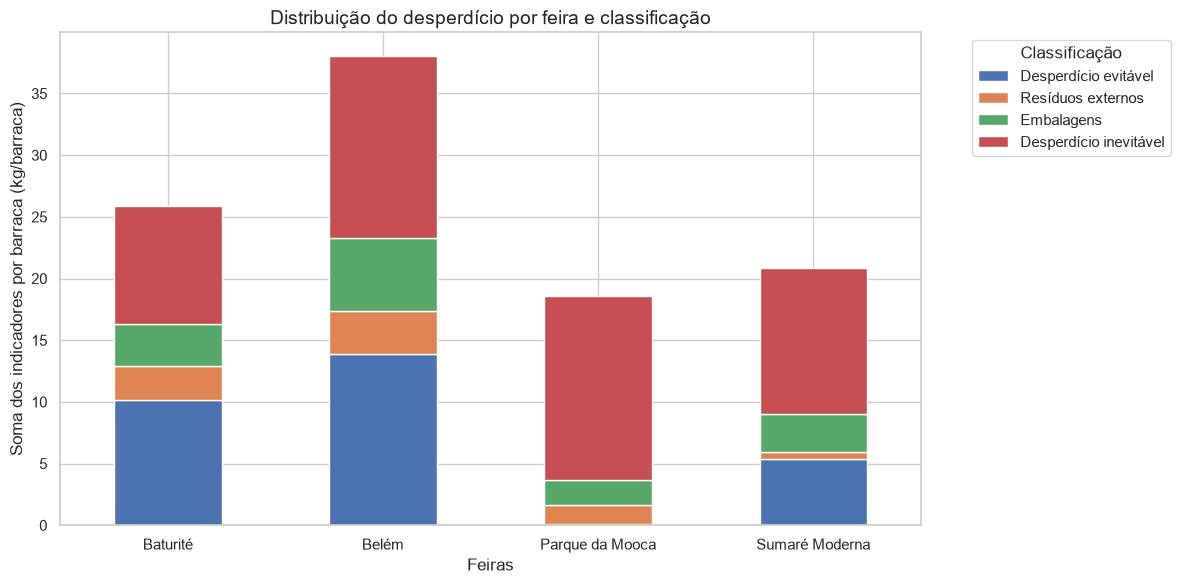

In [13]:
# Traduzir os nomes das classificações
nomes_classificacao = {
    "avoidable_food_waste": "Desperdício evitável",
    "unavoidable_food_waste": "Desperdício inevitável",
    "packaging": "Embalagens",
    "external_waste": "Resíduos externos"
}

# Renomear as colunas da tabela
grafico_classificacao = desperdicio_feira_classificacao.rename(
    columns=nomes_classificacao
)

# Criar gráfico de barras empilhadas
grafico_classificacao.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6)
)

# Configurar título e eixos
plt.title(
    "Distribuição do desperdício por feira e classificação",
    fontsize=14
)

plt.xlabel("Feiras")
plt.ylabel("Soma dos indicadores por barraca (kg/barraca)")

# Ajustar legenda
plt.legend(
    title="Classificação",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.xticks(rotation=0)
plt.tight_layout()

# Exibir gráfico
plt.show()

In [14]:
# Criar uma tabela com uma linha por feira
informacoes_feiras = df[
    ["market_id", "name", "district", "idh", "number_of_stalls"]
].drop_duplicates()

# Somar o desperdício evitável por feira, em kg por barraca
informacoes_evitaveis = dados_evitaveis.groupby(
    "market_id"
)["kg_per_stall"].sum()

# Associar o valor à tabela de feiras
informacoes_feiras = informacoes_feiras.merge(
    informacoes_evitaveis,
    on="market_id",
    how="left",
    validate="one_to_one"
)

# Renomear a coluna para explicitar a unidade
informacoes_feiras = informacoes_feiras.rename(
    columns={"kg_per_stall": "desperdicio_evitavel_kg_barraca"}
)

# Calcular o volume derivado usando o número de barracas do estudo
informacoes_feiras["desperdicio_evitavel_total_derivado_kg"] = (
    informacoes_feiras["desperdicio_evitavel_kg_barraca"]
    * informacoes_feiras["number_of_stalls"]
)

# Ordenar pelo volume derivado
informacoes_feiras = informacoes_feiras.sort_values(
    "desperdicio_evitavel_total_derivado_kg",
    ascending=False
).reset_index(drop=True)

# Exibir os resultados
display(informacoes_feiras.round(2))


,market_id,name,district,idh,number_of_stalls,desperdicio_evitavel_kg_barraca,desperdicio_evitavel_total_derivado_kg
0,SM4,Belém,Belenzinho,0.79,39,13.88,541.32
1,SM3,Baturité,Aclimação,0.82,40,10.14,405.60
2,SM2,Sumaré Moderna,Pacaembú,0.87,73,5.37,392.01
3,SM1,Parque da Mooca,Parque da Mooca,0.82,4,0.11,0.44


## 4. Volume derivado e participação do desperdício evitável

A soma simples dos valores em kg/barraca das quatro feiras não representa a participação percentual no volume total gerado, pois atribui o mesmo peso a feiras de portes diferentes. Para comparar volumes, multiplicamos cada valor por barraca pelo número de barracas informado no estudo.

Os resultados são **volumes derivados**, reconstruídos a partir dos indicadores publicados e do número de barracas. Não correspondem a uma nova pesagem. Os resíduos externos são apresentados separadamente, pois não representam desperdício alimentar.


In [15]:
# Calcular o volume derivado por classificação e feira
volume_por_classificacao = df[
    ["market_id", "classification", "kg_per_stall", "number_of_stalls"]
].copy()

volume_por_classificacao["kg_total_derivado"] = (
    volume_por_classificacao["kg_per_stall"]
    * volume_por_classificacao["number_of_stalls"]
)

# Somar os volumes derivados por classificação
totais_classificacao_derivados = volume_por_classificacao.groupby(
    "classification"
)["kg_total_derivado"].sum()

total_residuos_externos = totais_classificacao_derivados.loc["external_waste"]
total_evitavel_derivado = totais_classificacao_derivados.loc["avoidable_food_waste"]
total_com_externos = totais_classificacao_derivados.sum()
total_sem_externos = total_com_externos - total_residuos_externos

percentual_com_externos = (
    total_evitavel_derivado / total_com_externos
) * 100
percentual_sem_externos = (
    total_evitavel_derivado / total_sem_externos
) * 100

print("Total derivado com resíduos externos:", round(total_com_externos, 2), "kg")
print("Total derivado sem resíduos externos:", round(total_sem_externos, 2), "kg")
print("Desperdício evitável derivado:", round(total_evitavel_derivado, 2), "kg")
print("Evitável / total com resíduos externos:", round(percentual_com_externos, 2), "%")
print("Evitável / total sem resíduos externos:", round(percentual_sem_externos, 2), "%")

totais_classificacao_derivados.round(2)


Total derivado com resíduos externos: 4116.04 kg
Total derivado sem resíduos externos: 3822.48 kg
Desperdício evitável derivado: 1339.37 kg
Evitável / total com resíduos externos: 32.54 %
Evitável / total sem resíduos externos: 35.04 %


classification
avoidable_food_waste      1339.37
external_waste             293.56
packaging                  597.82
unavoidable_food_waste    1885.29
Name: kg_total_derivado, dtype: float64

### Interpretação dos volumes derivados

A ponderação pelo número de barracas altera a participação relativa das feiras em comparação com a soma simples dos indicadores por barraca. O percentual do desperdício evitável deve ser interpretado com atenção ao denominador: incluindo resíduos externos, o percentual é menor; excluindo essa categoria, o percentual considera somente as demais classificações registradas no estudo.

Esses valores são reconstruções baseadas nos dados publicados e sujeitos ao arredondamento das massas por barraca. Não devem ser apresentados como medições independentes nem extrapolados para feiras que não fizeram parte da pesquisa.


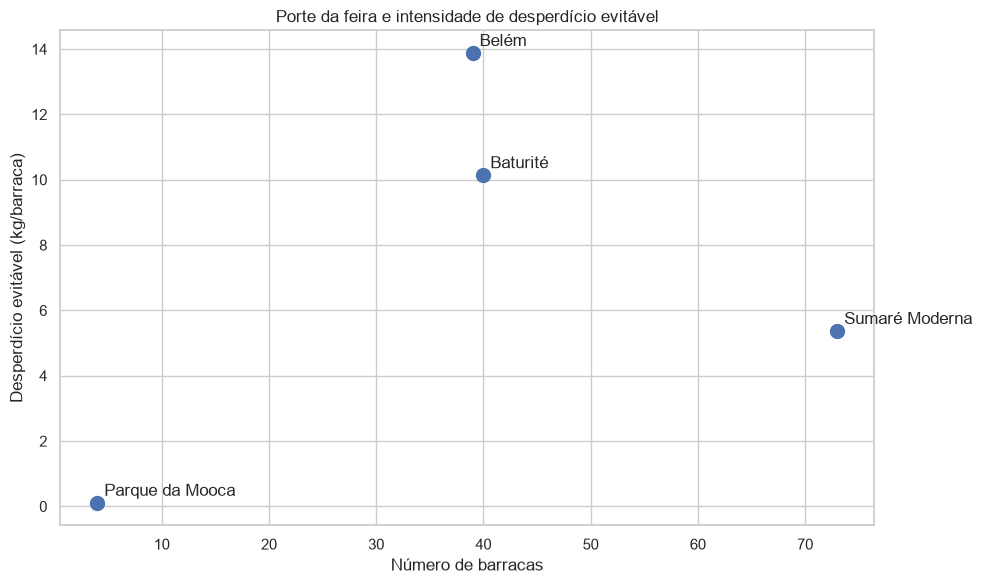

In [16]:
# Criar gráfico de dispersão
plt.figure(figsize=(10, 6))

plt.scatter(
    informacoes_feiras["number_of_stalls"],
    informacoes_feiras["desperdicio_evitavel_kg_barraca"],
    s=100
)

# Identificar cada feira no gráfico
for indice, linha in informacoes_feiras.iterrows():
    plt.annotate(
        linha["name"],
        (
            linha["number_of_stalls"],
            linha["desperdicio_evitavel_kg_barraca"]
        ),
        xytext=(5, 5),
        textcoords="offset points"
    )

# Configurar o gráfico
plt.title("Porte da feira e intensidade de desperdício evitável")
plt.xlabel("Número de barracas")
plt.ylabel("Desperdício evitável (kg/barraca)")
plt.grid(True)

plt.tight_layout()
plt.show()


### Cuidado na interpretação das correlações

A matriz é calculada após consolidar os dados em uma linha por feira. Portanto, a análise possui somente **quatro observações (n = 4)**. Ela é apresentada como exploração descritiva, não como evidência estatística de associação nem como base para inferência ou generalização.


In [17]:
# Consolidar em uma linha por feira para evitar repetição das mesmas feiras
dados_por_feira = df.groupby("market_id").agg(
    idh=("idh", "first"),
    number_of_stalls=("number_of_stalls", "first"),
    kg_per_stall_total=("kg_per_stall", "sum")
)

# Calcular separadamente o indicador de desperdício evitável
evitavel_por_feira = dados_evitaveis.groupby(
    "market_id"
)["kg_per_stall"].sum()

dados_por_feira["desperdicio_evitavel_kg_barraca"] = evitavel_por_feira

# Matriz descritiva com quatro feiras (n = 4)
matriz_correlacao = dados_por_feira[
    [
        "idh",
        "number_of_stalls",
        "kg_per_stall_total",
        "desperdicio_evitavel_kg_barraca"
    ]
].corr()

display(dados_por_feira.round(2))
matriz_correlacao.round(2)


,idh,number_of_stalls,kg_per_stall_total,desperdicio_evitavel_kg_barraca
market_id,,,,
SM1,0.82,4,18.56,0.11
SM2,0.87,73,20.88,5.37
SM3,0.82,40,25.85,10.14
SM4,0.79,39,38.04,13.88


,idh,number_of_stalls,kg_per_stall_total,desperdicio_evitavel_kg_barraca
idh,1.00,0.61,-0.71,-0.48
number_of_stalls,0.61,1.00,0.12,0.37
kg_per_stall_total,-0.71,0.12,1.00,0.91
desperdicio_evitavel_kg_barraca,-0.48,0.37,0.91,1.00


## 5. Contexto territorial das quatro feiras do estudo

A integração exploratória com a relação municipal da Prefeitura acrescenta informações de subprefeitura, bairro e logradouro aos registros de Brancoli et al. (2022). A tabela abaixo apresenta uma linha por feira, evitando repetir as informações territoriais nas 26 categorias de cada mercado.

As quatro correspondências identificadas concentram-se em duas subprefeituras: **Mooca** e **Sé**. Esse recorte reforça a limitação territorial da amostra e não deve ser generalizado para a cidade inteira.


In [18]:
colunas_territoriais = [
    "market_id",
    "name",
    "district",
    "nome_feira_municipal",
    "subprefeitura",
    "bairro_municipal",
    "logradouro",
    "status_correspondencia"
]

feiras_territoriais = df[colunas_territoriais].drop_duplicates(
    subset="market_id"
).sort_values("market_id")

display(feiras_territoriais)

print(
    "Quantidade de feiras na amostra:",
    feiras_territoriais["market_id"].nunique()
)
print(
    "Subprefeituras representadas:",
    sorted(feiras_territoriais["subprefeitura"].dropna().unique())
)
print(
    "Quantidade de subprefeituras:",
    feiras_territoriais["subprefeitura"].nunique()
)


,market_id,name,district,nome_feira_municipal,subprefeitura,bairro_municipal,logradouro,status_correspondencia
0,SM1,Parque da Mooca,Parque da Mooca,PARQUE DA MOOCA,MOOCA,PQ DA MOOCA,CONDE PRATES,exploratoria_consistente
1,SM2,Sumaré Moderna,Pacaembú,SUMARE MODERNA,SE,PACAEMBU,CHARLES MULLER,exploratoria_consistente
2,SM3,Baturité,Aclimação,BATURITE,SE,ACLIMACAO,OLIVEIRA PEIXOTO,exploratoria_consistente
3,SM4,Belém,Belenzinho,BELEM,MOOCA,BELENZINHO,IRMA CAROLINA,exploratoria_consistente


Quantidade de feiras na amostra: 4
Subprefeituras representadas: ['MOOCA', 'SE']
Quantidade de subprefeituras: 2


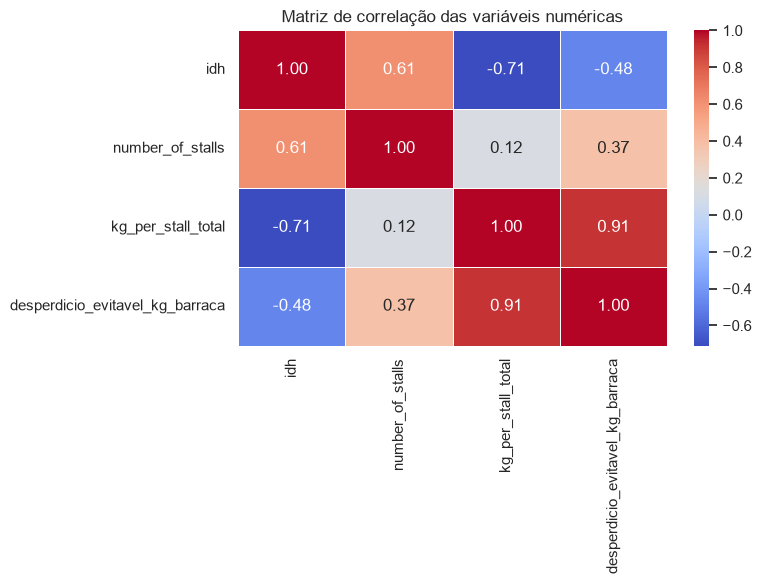

In [19]:
# Criar o tamanho da figura
plt.figure(figsize=(8, 6))

# Criar o mapa de calor
sns.heatmap(
    matriz_correlacao,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

# Configurar o título
plt.title("Matriz de correlação das variáveis numéricas")

# Exibir o gráfico
plt.tight_layout()
plt.show()

In [20]:
# Filtrar somente os resíduos alimentares evitáveis
dados_evitaveis = df[
    df["classification"] == "avoidable_food_waste"
].copy()

# Criar uma identificação que combine os dois níveis de categoria
dados_evitaveis["categoria_completa"] = (
    dados_evitaveis["category_level_I"]
    + " - "
    + dados_evitaveis["category_level_II"]
)

# Agrupar pelas categorias de nível I e II
desperdicio_por_alimento = dados_evitaveis.groupby(
    ["category_level_I", "category_level_II"]
)["kg_per_stall"].sum()

# Ordenar do maior para o menor
desperdicio_por_alimento = desperdicio_por_alimento.sort_values(
    ascending=False
)

# Exibir o resultado
desperdicio_por_alimento


category_level_I          category_level_II       
Leaves flowers and stems  Other                       15.52
Meat                      Meat                         4.83
Fruits                    Other                        3.58
Vegetables                Tomato                       1.62
Fruits                    Orange                       0.96
Vegetables                Other                        0.72
Fruits                    Banana                       0.63
Tubers bulbs and roots    Potato                       0.40
                          Onion                        0.30
Fruits                    Watermelon                   0.23
Leaves flowers and stems  Broccoli and cauliflower     0.20
Fruits                    Papaya                       0.19
Tubers bulbs and roots    Other                        0.16
                          Carrot                       0.09
Vegetables                Pumpkin                      0.05
Processed products        Tubers bulbs and roots 

In [21]:
# Filtrar somente as subcategorias chamadas Other
dados_other = dados_evitaveis[
    dados_evitaveis["category_level_II"] == "Other"
]

# Agrupar por categoria de nível I
other_por_grupo = dados_other.groupby(
    "category_level_I"
)["kg_per_stall"].sum()

# Ordenar do maior para o menor
other_por_grupo = other_por_grupo.sort_values(
    ascending=False
)

# Exibir os resultados
other_por_grupo


category_level_I
Leaves flowers and stems    15.52
Fruits                       3.58
Vegetables                   0.72
Tubers bulbs and roots       0.16
Name: kg_per_stall, dtype: float64

In [22]:
# Somar todo o desperdício evitável
total_evitavel = dados_evitaveis["kg_per_stall"].sum()

# Somar os valores das subcategorias Other, mantendo os grupos separados
total_other = other_por_grupo.sum()

# Calcular a participação conjunta das subcategorias Other
percentual_other = (total_other / total_evitavel) * 100

# Calcular a participação de cada grupo Other no total evitável
participacao_other_por_grupo = (
    other_por_grupo / total_evitavel
) * 100

print("Total de desperdício evitável:", round(total_evitavel, 2), "kg/barraca")
print("Soma não ponderada das subcategorias Other:", round(total_other, 2), "kg/barraca")
print("Participação não ponderada conjunta de Other:", round(percentual_other, 2), "%")

display(participacao_other_por_grupo.round(2))


Total de desperdício evitável: 29.5 kg/barraca
Soma não ponderada das subcategorias Other: 19.98 kg/barraca
Participação não ponderada conjunta de Other: 67.73 %


category_level_I
Leaves flowers and stems    52.61
Fruits                      12.14
Vegetables                   2.44
Tubers bulbs and roots       0.54
Name: kg_per_stall, dtype: float64

In [23]:
# Agrupar desperdício evitável por grupo e subcategoria
participacao_alimentos = dados_evitaveis.groupby(
    ["category_level_I", "category_level_II"]
)["kg_per_stall"].sum().reset_index()

# Percentual não ponderado: cada feira contribui com seu indicador em kg/barraca
total_nao_ponderado = participacao_alimentos["kg_per_stall"].sum()
participacao_alimentos["percentual_nao_ponderado"] = (
    participacao_alimentos["kg_per_stall"] / total_nao_ponderado
) * 100

# Para a visão ponderada, multiplicar o indicador de cada categoria pelo número
# de barracas da respectiva feira e somar os volumes derivados.
dados_evitaveis_ponderados = dados_evitaveis.copy()
dados_evitaveis_ponderados["kg_total_derivado"] = (
    dados_evitaveis_ponderados["kg_per_stall"]
    * dados_evitaveis_ponderados["number_of_stalls"]
)

participacao_ponderada = dados_evitaveis_ponderados.groupby(
    ["category_level_I", "category_level_II"]
)["kg_total_derivado"].sum().reset_index()

total_ponderado = participacao_ponderada["kg_total_derivado"].sum()
participacao_ponderada["percentual_ponderado_barracas"] = (
    participacao_ponderada["kg_total_derivado"] / total_ponderado
) * 100

# Unir as duas visões na mesma tabela
participacao_alimentos = participacao_alimentos.merge(
    participacao_ponderada[
        ["category_level_I", "category_level_II", "percentual_ponderado_barracas"]
    ],
    on=["category_level_I", "category_level_II"],
    how="left",
    validate="one_to_one"
)

participacao_alimentos["categoria_completa"] = (
    participacao_alimentos["category_level_I"]
    + " - "
    + participacao_alimentos["category_level_II"]
)

participacao_alimentos = participacao_alimentos.sort_values(
    "percentual_nao_ponderado",
    ascending=False
).set_index("categoria_completa")

display(
    participacao_alimentos[
        ["percentual_nao_ponderado", "percentual_ponderado_barracas"]
    ].round(2)
)


,percentual_nao_ponderado,percentual_ponderado_barracas
categoria_completa,,
Leaves flowers and stems - Other,52.61,48.67
Meat - Meat,16.37,22.82
Fruits - Other,12.14,10.75
Vegetables - Tomato,5.49,4.57
Fruits - Orange,3.25,3.30
Vegetables - Other,2.44,2.94
Fruits - Banana,2.14,1.89
Tubers bulbs and roots - Potato,1.36,1.22
Tubers bulbs and roots - Onion,1.02,0.88


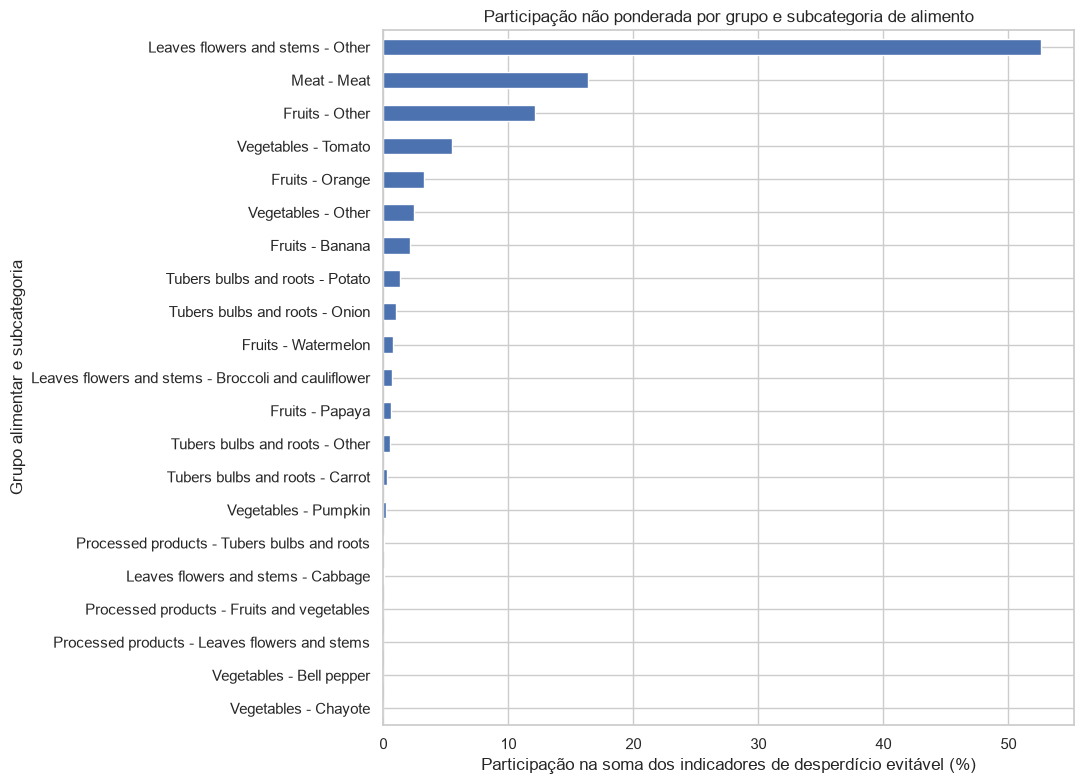

In [24]:
# Criar o gráfico da participação percentual não ponderada
plt.figure(figsize=(11, 8))

participacao_alimentos["percentual_nao_ponderado"].plot(
    kind="barh"
)

# Configurar o gráfico
plt.title("Participação não ponderada por grupo e subcategoria de alimento")
plt.xlabel("Participação na soma dos indicadores de desperdício evitável (%)")
plt.ylabel("Grupo alimentar e subcategoria")

# Inverter a ordem para deixar a maior categoria no topo
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()


## 6. Participação por grupo e subcategoria de alimento

A análise considera conjuntamente as categorias de nível I e nível II da Tabela 3 de Brancoli et al. (2022). Essa separação evita reunir em uma única linha os diferentes grupos alimentares identificados como **Other**.

A tabela apresenta duas perspectivas:

- **Percentual não ponderado:** soma os indicadores em kg/barraca das quatro feiras, atribuindo o mesmo peso a cada feira.
- **Percentual ponderado pelo número de barracas:** multiplica o indicador de cada categoria pelo número de barracas da respectiva feira e soma os volumes derivados. Feiras maiores passam a contribuir proporcionalmente mais.

As duas medidas respondem a perguntas diferentes e não devem ser confundidas. A ponderação é uma estimativa derivada a partir da média por barraca e do número de barracas informado no estudo; não representa uma nova pesagem observada.

O artigo identifica os grupos alimentares, mas não discrimina individualmente todos os alimentos reunidos em cada subcategoria **Other**. Portanto, a limitação está na identificação dos produtos específicos, e não na ausência de classificação por grupo alimentar.


In [25]:
# Agrupar o desperdício evitável por feira e pelas duas categorias
desperdicio_categoria_feira = dados_evitaveis.pivot_table(
    index=["category_level_I", "category_level_II"],
    columns="name",
    values="kg_per_stall",
    aggfunc="sum",
    fill_value=0
)

# Exibir a tabela
desperdicio_categoria_feira


name                                               Baturité  Belém  \
category_level_I         category_level_II                           
Fruits                   Banana                        0.40   0.22   
                         Orange                        0.24   0.53   
                         Other                         0.58   2.89   
                         Papaya                        0.09   0.07   
                         Watermelon                    0.22   0.00   
Leaves flowers and stems Broccoli and cauliflower      0.03   0.17   
                         Cabbage                       0.00   0.00   
                         Other                         6.80   7.55   
Meat                     Meat                          1.35   0.07   
Processed products       Fruits and vegetables         0.00   0.00   
                         Leaves flowers and stems      0.00   0.00   
                         Tubers bulbs and roots        0.01   0.00   
Tubers bulbs and roots   Carrot                        0.02   0.07   
                         Onion                         0.04   0.26   
                         Other                         0.00   0.16   
                         Potato                        0.02   0.36   
Vegetables               Bell pepper                   0.00   0.00   
                         Chayote                       0.00   0.00   
                         Other                         0.10   0.29   
                         Pumpkin                       0.00   0.02   
                         Tomato                        0.24   1.22   

name                                               Parque da Mooca  \
category_level_I         category_level_II                           
Fruits                   Banana                               0.00   
                         Orange                               0.00   
                         Other                                0.00   
                         Papaya                               0.00   
                         Watermelon                           0.00   
Leaves flowers and stems Broccoli and cauliflower             0.00   
                         Cabbage                              0.00   
                         Other                                0.00   
Meat                     Meat                                 0.00   
Processed products       Fruits and vegetables                0.00   
                         Leaves flowers and stems             0.00   
                         Tubers bulbs and roots               0.00   
Tubers bulbs and roots   Carrot                               0.00   
                         Onion                                0.00   
                         Other                                0.00   
                         Potato                               0.00   
Vegetables               Bell pepper                          0.00   
                         Chayote                              0.00   
                         Other                                0.00   
                         Pumpkin                              0.00   
                         Tomato                               0.11   

name                                               Sumaré Moderna  
category_level_I         category_level_II                         
Fruits                   Banana                              0.01  
                         Orange                              0.19  
                         Other                               0.11  
                         Papaya                              0.03  
                         Watermelon                          0.01  
Leaves flowers and stems Broccoli and cauliflower            0.00  
                         Cabbage                             0.01  
                         Other                               1.17  
Meat                     Meat                                3.41  
Processed products       Fruit

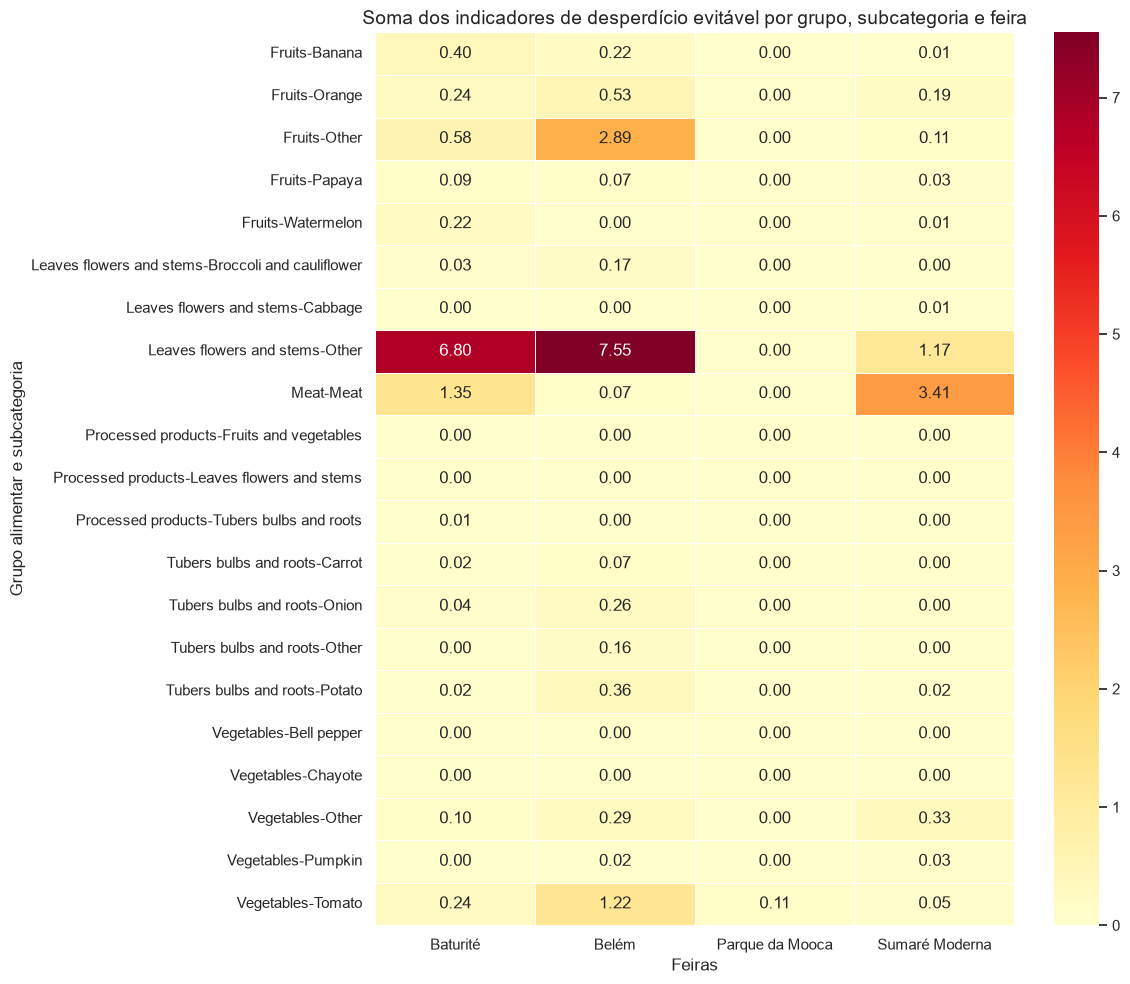

In [26]:
# Criar o tamanho da figura
plt.figure(figsize=(12, 10))

# Criar o mapa de calor
sns.heatmap(
    desperdicio_categoria_feira,
    annot=True,
    cmap="YlOrRd",
    fmt=".2f",
    linewidths=0.5
)

# Configurar o gráfico
plt.title(
    "Soma dos indicadores de desperdício evitável por grupo, subcategoria e feira",
    fontsize=14
)

plt.xlabel("Feiras")
plt.ylabel("Grupo alimentar e subcategoria")

# Ajustar a apresentação
plt.tight_layout()

# Exibir o gráfico
plt.show()


### 6.1. Distribuição do desperdício evitável por feira e categoria

O mapa de calor apresenta a soma dos indicadores em kg/barraca das quatro feiras, separada por grupo alimentar (categoria de nível I) e subcategoria (nível II). Portanto, os valores permitem comparar a composição registrada entre as feiras, mas não representam o volume total de resíduos de cada feira. Assim, as linhas chamadas **Other** permanecem distintas para folhas, flores e talos; frutas; vegetais; e tubérculos, bulbos e raízes.

A feira Belém apresentou valores elevados em subcategorias do grupo de folhas, flores e talos e em frutas. Baturité destacou-se nas categorias **Banana** e **Meat**, enquanto Sumaré Moderna apresentou o maior valor de desperdício na categoria **Meat**.

Parque da Mooca apresentou valores reduzidos nas categorias analisadas. As diferenças são observações específicas das quatro feiras estudadas por Brancoli et al. (2022), sem generalização automática para todas as feiras livres de São Paulo.


## 7. Conclusões, achados principais e limitações

### Principais achados

- A base analítica contém **104 registros**, correspondentes a 26 categorias transcritas para cada uma das **quatro feiras** estudadas.
- O indicador de desperdício evitável pode ser comparado por feira e por grupo alimentar, mantendo as duas dimensões da classificação da Tabela 3.
- A participação por categoria muda quando se considera o número de barracas. Por isso, este notebook apresenta tanto a composição não ponderada (kg/barraca) quanto a participação ponderada por barracas (volume derivado).
- A integração exploratória com a relação municipal localiza as quatro feiras em **duas subprefeituras: Mooca e Sé**. Esse resultado descreve apenas as feiras da amostra do artigo, não a distribuição de todas as feiras municipais.

### Limitações e decisões metodológicas

1. **Tamanho e período da amostra:** o estudo de Brancoli et al. (2022) observou quatro feiras durante uma semana de dezembro de 2021. A amostra não representa automaticamente todas as feiras, estações do ano ou condições operacionais de São Paulo.
2. **Contexto socioeconômico:** os valores de IDH das quatro áreas variam de 0,790 a 0,868. A concentração em áreas de IDH relativamente alto limita a generalização para territórios com outros perfis socioeconômicos.
3. **Unidade de análise:** as somas da Seção 3 e a participação não ponderada da Seção 6 agregam indicadores em kg/barraca das quatro feiras; não são totais municipais. `kg_per_stall` é um indicador por barraca. A multiplicação pelo número de barracas produz um volume derivado, sujeito a arredondamentos e às hipóteses do cálculo.
4. **Resíduos externos:** a Seção 3.1 do artigo apresenta a faixa de 17 a 34,6 kg/barraca para o desperdício das feiras sem os resíduos externos. A Tabela 2 inclui o total de resíduos, portanto as duas medidas não devem ser comparadas sem explicitar essa diferença.
5. **Categorias da Tabela 3:** o texto do artigo menciona 27 frações, enquanto a tabela transcrita apresenta 26 entradas por feira. A análise preserva as entradas efetivamente publicadas na tabela e registra a divergência, sem criar uma categoria ausente.
6. **Correspondência territorial:** o vínculo com a base da Prefeitura é exploratório, baseado em nome, dia e bairro. Não há identificador oficial compartilhado no artigo para confirmar cada correspondência.
7. **Machine Learning:** esta base é adequada para diagnóstico exploratório e justificativa do problema, mas quatro feiras não sustentam uma divisão treino/validação/teste confiável nem uma avaliação robusta de modelos supervisionados.

### Próxima etapa

A relação municipal de 933 feiras será analisada separadamente para descrever a distribuição territorial, os dias de funcionamento e as categorias cadastradas. Essa base não contém medidas de desperdício por feira; portanto, não deve ser tratada como variável-alvo de previsão sem uma fonte adicional ou uma estratégia de estimativa explicitamente documentada.
